# Realce, índices y transformaciones

Una vez corregida, la imagen se puede realzar para facilitar la interpretación visual, o transformar para resumir o resaltar la información que interesa. El realce cambia la forma en que se muestran los datos sin cambiar los datos; los índices y las transformaciones crean bandas nuevas a partir de las originales {cite}`chuvieco2008,richards2013`.

Para todo el capítulo se usa una escena sintética de 300 × 300 píxeles con seis bandas (azul, verde, rojo, infrarrojo cercano y dos de infrarrojo de onda corta) y cinco coberturas: agua, bosque, pasto, suelo desnudo y roca con alteración arcillosa. La función que la genera se define en la celda siguiente.

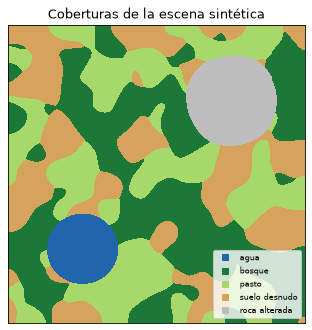

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage
plt.rcParams['figure.dpi'] = 75

BANDAS = ['azul', 'verde', 'rojo', 'NIR', 'SWIR1', 'SWIR2']
FIRMAS = {   # reflectancia media por banda
    'agua':           [0.06, 0.05, 0.03, 0.01, 0.005, 0.003],
    'bosque':         [0.03, 0.06, 0.03, 0.38, 0.17, 0.07],
    'pasto':          [0.05, 0.09, 0.07, 0.30, 0.25, 0.14],
    'suelo desnudo':  [0.09, 0.13, 0.18, 0.25, 0.32, 0.27],
    'roca alterada':  [0.17, 0.22, 0.26, 0.31, 0.40, 0.24],
}
COLORES = ['#2166ac', '#1b7837', '#a6d96a', '#d6a35c', '#bdbdbd']

def escena(n=300, semilla=0):
    rng = np.random.default_rng(semilla)
    campos = [ndimage.gaussian_filter(rng.normal(0, 1, (n, n)), 12) for _ in FIRMAS]
    yy, xx = np.mgrid[0:n, 0:n]
    campos[0] += 4 * np.exp(-((xx - 0.25 * n)**2 + (yy - 0.75 * n)**2) / (0.12 * n)**2) - 1.5   # un lago
    campos[4] += 3 * np.exp(-((xx - 0.75 * n)**2 + (yy - 0.25 * n)**2) / (0.15 * n)**2) - 1.0   # zona de alteración
    clases = np.argmax(np.array(campos), axis=0)
    img = np.zeros((len(BANDAS), n, n))
    for k, f in enumerate(FIRMAS.values()):
        m = clases == k
        variab = 1 + 0.12 * ndimage.gaussian_filter(rng.normal(0, 1, (n, n)), 3)[m]
        for b in range(len(BANDAS)):
            img[b][m] = f[b] * variab + rng.normal(0, 0.006, m.sum())
    return np.clip(img, 0, 1), clases

img, clases = escena()
from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(clases, cmap=ListedColormap(COLORES), interpolation='nearest')
ax.set_title('Coberturas de la escena sintética'); ax.set_xticks([]); ax.set_yticks([])
for k, nom in enumerate(FIRMAS):
    ax.plot([], [], 's', color=COLORES[k], label=nom)
ax.legend(fontsize=8, loc='lower right'); plt.tight_layout(); plt.show()

## Composiciones en color

Una pantalla tiene tres canales, rojo, verde y azul, y a cada uno se le puede asignar una banda. La composición en color natural asigna las bandas roja, verde y azul a sus canales homólogos y muestra la escena como la vería el ojo. La composición en falso color infrarrojo (NIR, rojo, verde) muestra la vegetación sana en rojo intenso, porque refleja mucho en el infrarrojo cercano, y es la más usada para vegetación y para delimitar el agua, que se ve negra. Las composiciones con el infrarrojo de onda corta (SWIR2, NIR, rojo, o SWIR1, NIR, azul) separan bien los suelos, las rocas y la humedad, y son las preferidas en geología. La elección de la combinación depende de lo que se quiere resaltar.

## Realce del contraste

Los valores de reflectancia de una escena suelen ocupar una parte pequeña del intervalo que la pantalla puede mostrar, y la imagen se ve oscura y sin contraste. El realce redistribuye los valores. La expansión lineal asigna el mínimo y el máximo de la banda a los extremos de la pantalla; como unos pocos píxeles extremos la arruinan, se suele recortar un porcentaje en cada extremo, por ejemplo el 2 %. La ecualización del histograma reparte los valores para que todos los niveles de la pantalla tengan aproximadamente el mismo número de píxeles, lo que realza los contrastes en los valores más frecuentes a costa de los raros.

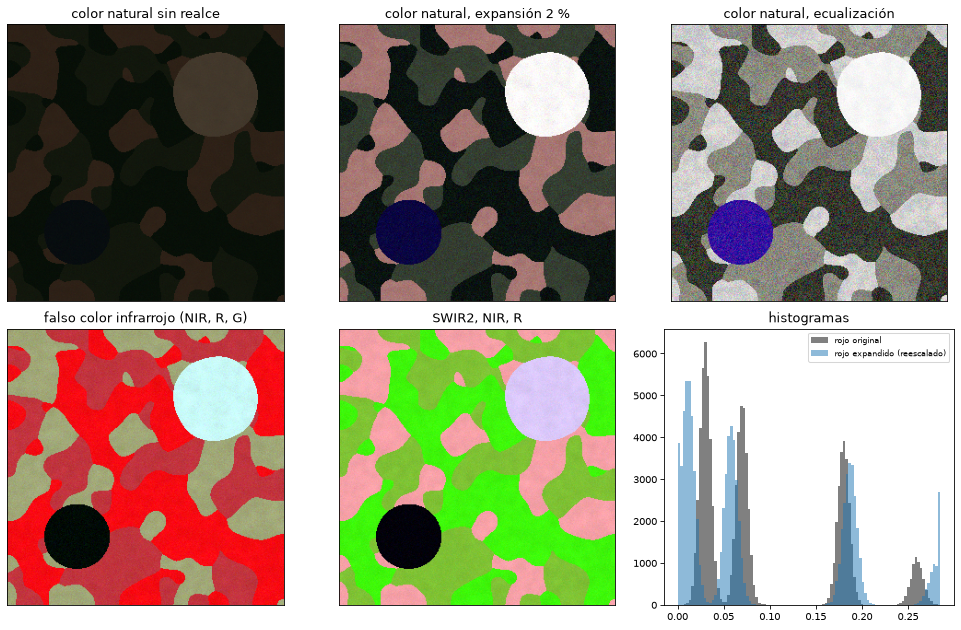

In [2]:
def expandir(b, p=2):
    lo, hi = np.percentile(b, [p, 100 - p])
    return np.clip((b - lo) / (hi - lo), 0, 1)

def ecualizar(b, niveles=256):
    hist, bordes = np.histogram(b, niveles)
    cdf = hist.cumsum() / hist.sum()
    return np.interp(b, bordes[:-1], cdf)

def rgb(r, g, b, f=expandir):
    return np.dstack([f(r), f(g), f(b)])

i = {n: k for k, n in enumerate(BANDAS)}
fig, axs = plt.subplots(2, 3, figsize=(13, 8.5))
axs[0, 0].imshow(np.clip(np.dstack([img[i['rojo']], img[i['verde']], img[i['azul']]]), 0, 1)); axs[0, 0].set_title('color natural sin realce')
axs[0, 1].imshow(rgb(img[i['rojo']], img[i['verde']], img[i['azul']])); axs[0, 1].set_title('color natural, expansión 2 %')
axs[0, 2].imshow(rgb(img[i['rojo']], img[i['verde']], img[i['azul']], ecualizar)); axs[0, 2].set_title('color natural, ecualización')
axs[1, 0].imshow(rgb(img[i['NIR']], img[i['rojo']], img[i['verde']])); axs[1, 0].set_title('falso color infrarrojo (NIR, R, G)')
axs[1, 1].imshow(rgb(img[i['SWIR2']], img[i['NIR']], img[i['rojo']])); axs[1, 1].set_title('SWIR2, NIR, R')
axs[1, 2].hist(img[i['rojo']].ravel(), 100, color='0.5', label='rojo original')
axs[1, 2].hist(expandir(img[i['rojo']]).ravel() * img[i['rojo']].max(), 100, alpha=0.5, label='rojo expandido (reescalado)')
axs[1, 2].set_title('histogramas'); axs[1, 2].legend(fontsize=8)
for a in axs.ravel()[:5]: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Filtros espaciales

Los filtros modifican el valor de cada píxel según el de sus vecinos, mediante una convolución con una ventana o núcleo. Los filtros de paso bajo, como la media o la gaussiana, suavizan la imagen y reducen el ruido; el de mediana lo hace conservando mejor los bordes. Los de paso alto, como el laplaciano, realzan los cambios bruscos. Los direccionales, como el de Sobel, realzan los bordes en una dirección determinada, y en geología se usan para resaltar lineamientos de una orientación dada, por ejemplo sobre un sombreado del relieve.

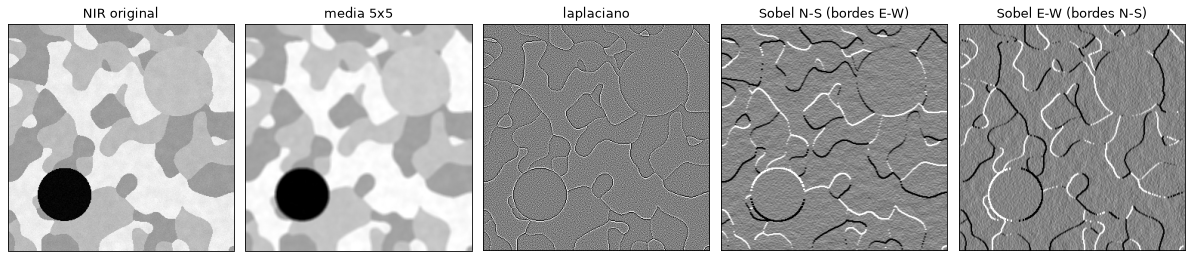

In [3]:
b = img[i['NIR']]
nucleos = {'media 5x5': np.ones((5, 5)) / 25,
           'laplaciano': np.array([[0, -1, 0], [-1, 4, -1], [0, -1, 0]]),
           'Sobel N-S (bordes E-W)': np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]]),
           'Sobel E-W (bordes N-S)': np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]])}
fig, axs = plt.subplots(1, 5, figsize=(16, 3.6))
axs[0].imshow(b, cmap='gray'); axs[0].set_title('NIR original')
for a, (nom, k) in zip(axs[1:], nucleos.items()):
    a.imshow(expandir(ndimage.convolve(b, k)), cmap='gray'); a.set_title(nom)
for a in axs: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Cocientes e índices

Un cociente entre bandas resalta las diferencias en la forma de la firma espectral y atenúa el efecto de la iluminación, que multiplica por igual a las dos bandas: una ladera en sombra y una iluminada de la misma cobertura tienen distinto brillo pero casi el mismo cociente. Los índices normalizados, de la forma $(a - b)/(a + b)$, varían entre -1 y 1.

El índice de vegetación de diferencia normalizada {cite}`rouse1974`,

$$\mathrm{NDVI} = \frac{\mathrm{NIR} - \mathrm{R}}{\mathrm{NIR} + \mathrm{R}},$$

aprovecha el contraste entre la absorción del rojo por la clorofila y la alta reflexión del infrarrojo cercano: es mayor de 0.6 en vegetación densa y sana, cercano a 0.1 o 0.2 en suelos desnudos y negativo en el agua. El NDWI de McFeeters, $(\mathrm{G} - \mathrm{NIR})/(\mathrm{G} + \mathrm{NIR})$, resalta el agua. En geología son útiles los cocientes que detectan minerales: SWIR1/SWIR2 resalta los minerales arcillosos y las micas, que absorben cerca de 2.2 µm (banda SWIR2), y rojo/azul resalta los óxidos de hierro. El NBR, $(\mathrm{NIR} - \mathrm{SWIR2})/(\mathrm{NIR} + \mathrm{SWIR2})$, se usa para áreas quemadas y, con su diferencia entre dos fechas, para cartografiar cicatrices de incendios y de deslizamientos recientes. Como la vegetación también tiene un cociente SWIR1/SWIR2 alto, por la absorción del agua de las hojas en el SWIR2, el cociente de arcillas solo se interpreta donde el NDVI es bajo; es un ejemplo de por qué los índices se combinan entre sí. La base de datos de índices (indexdatabase.de) recoge cientos de ellos.

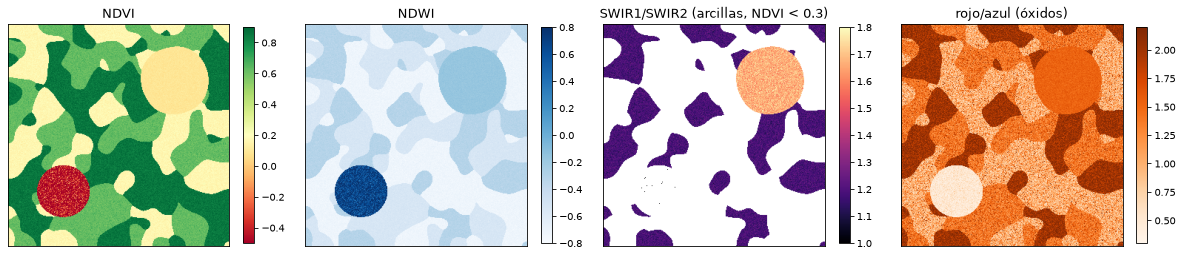

agua           NDVI  -0.52   NDWI   0.68   SWIR1/SWIR2  0.28   R/A  0.51
bosque         NDVI   0.85   NDWI  -0.73   SWIR1/SWIR2   nan   R/A  1.05
pasto          NDVI   0.62   NDWI  -0.54   SWIR1/SWIR2   nan   R/A  1.42
suelo desnudo  NDVI   0.16   NDWI  -0.32   SWIR1/SWIR2  1.19   R/A  2.01
roca alterada  NDVI   0.09   NDWI  -0.17   SWIR1/SWIR2  1.67   R/A  1.53


In [4]:
eps = 1e-6
ndvi = (img[i['NIR']] - img[i['rojo']]) / (img[i['NIR']] + img[i['rojo']] + eps)
ndwi = (img[i['verde']] - img[i['NIR']]) / (img[i['verde']] + img[i['NIR']] + eps)
arcillas = img[i['SWIR1']] / (img[i['SWIR2']] + eps)
arcillas = np.where((ndvi < 0.3) & (img[i['SWIR2']] > 0.02), arcillas, np.nan)   # solo donde no hay vegetación ni agua
oxidos = img[i['rojo']] / (img[i['azul']] + eps)
fig, axs = plt.subplots(1, 4, figsize=(16, 3.9))
for a, (nom, x, cm, lim) in zip(axs, [('NDVI', ndvi, 'RdYlGn', (-0.5, 0.9)), ('NDWI', ndwi, 'Blues', (-0.8, 0.8)),
                                      ('SWIR1/SWIR2 (arcillas, NDVI < 0.3)', arcillas, 'magma', (1, 1.8)), ('rojo/azul (óxidos)', oxidos, 'Oranges', (0.3, 2.2))]):
    h = a.imshow(x, cmap=cm, vmin=lim[0], vmax=lim[1]); a.set_title(nom); a.set_xticks([]); a.set_yticks([])
    fig.colorbar(h, ax=a, shrink=0.8)
plt.tight_layout(); plt.show()
for k, nom in enumerate(FIRMAS):
    m = clases == k
    print(f'{nom:14s} NDVI {ndvi[m].mean():6.2f}   NDWI {ndwi[m].mean():6.2f}   SWIR1/SWIR2 {np.nanmean(arcillas[m]) if np.isfinite(arcillas[m]).any() else np.nan:5.2f}   R/A {oxidos[m].mean():5.2f}')

## Análisis de componentes principales

Las bandas de una imagen están muy correlacionadas: lo que es brillante en el verde suele serlo en el rojo. El análisis de componentes principales (ACP) rota el espacio de las bandas para obtener nuevas variables no correlacionadas, ordenadas por la varianza que explican. El primer componente suele representar el brillo general de la escena, y el segundo y tercero, los contrastes espectrales, como el de la vegetación frente al suelo. Los últimos componentes concentran el ruido. El ACP sirve para comprimir la información, para realzar contrastes sutiles y, aplicado a imágenes de dos fechas, para detectar cambios. Una aplicación clásica en exploración es la técnica de Crósta, que aplica el ACP a un subconjunto de bandas seleccionado para que un componente concentre la respuesta de un mineral de alteración.

Varianza explicada por componente (%): [73.  22.2  3.6  1.   0.1  0.1]
Cargas (filas = bandas, columnas = CP1 a CP3):
  azul   [-0.23 -0.07  0.5 ]
  verde  [-0.28  0.02  0.46]
  rojo   [-0.49 -0.06  0.35]
  NIR    [0.14 0.94 0.09]
  SWIR1  [-0.55  0.31 -0.09]
  SWIR2  [-0.55  0.   -0.63]


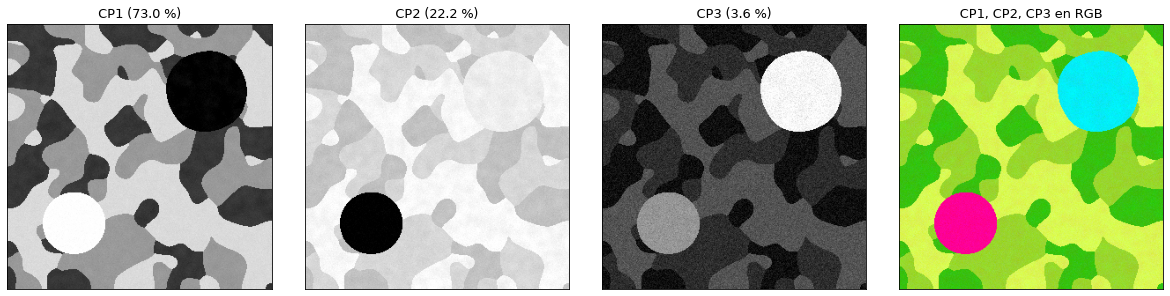

In [5]:
X = img.reshape(len(BANDAS), -1).T
Xc = X - X.mean(axis=0)
cov = np.cov(Xc, rowvar=False)
val, vec = np.linalg.eigh(cov)
orden = np.argsort(val)[::-1]; val, vec = val[orden], vec[:, orden]
cp = (Xc @ vec).T.reshape(len(BANDAS), *img.shape[1:])
print('Varianza explicada por componente (%):', np.round(100 * val / val.sum(), 1))
print('Cargas (filas = bandas, columnas = CP1 a CP3):')
for nom, fila in zip(BANDAS, vec[:, :3]):
    print(f'  {nom:6s}', np.round(fila, 2))
fig, axs = plt.subplots(1, 4, figsize=(16, 3.9))
for k in range(3):
    axs[k].imshow(expandir(cp[k]), cmap='gray'); axs[k].set_title(f'CP{k+1} ({100*val[k]/val.sum():.1f} %)')
axs[3].imshow(rgb(cp[0], cp[1], cp[2])); axs[3].set_title('CP1, CP2, CP3 en RGB')
for a in axs: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Otras transformaciones

La transformación tasseled cap {cite}`kauth1976` es una rotación fija, con coeficientes publicados para cada sensor, que produce tres componentes con significado físico: brillo (suelos), verdor (vegetación) y humedad. A diferencia del ACP, sus coeficientes no dependen de la escena, lo que permite comparar imágenes. La transformación de RGB a intensidad, matiz y saturación (IHS) separa el color del brillo y se usa para fusionar imágenes: el pan-sharpening sustituye la intensidad de una composición multiespectral por la banda pancromática, de mayor resolución, y vuelve a RGB, de modo que se obtiene una imagen en color con el detalle de la pancromática. La celda siguiente ilustra la idea con una versión simple, la fusión de Brovey, que multiplica cada banda por el cociente entre la pancromática y la intensidad.

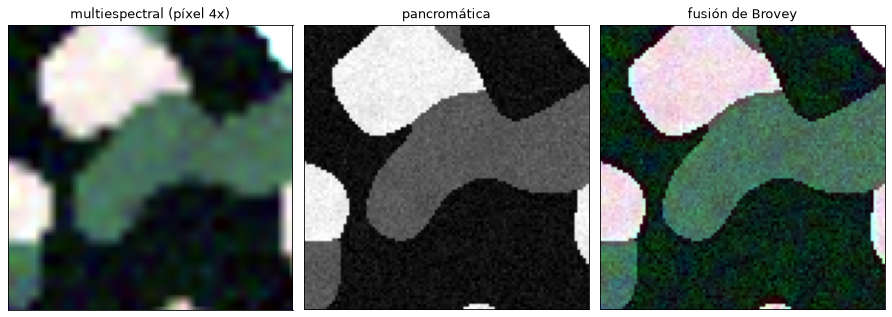

In [6]:
alta = img[[i['rojo'], i['verde'], i['azul']]]
pan = alta.mean(axis=0)                                        # pancromática con la resolución completa
baja = np.array([ndimage.zoom(ndimage.zoom(bd, 1 / 4, order=1), 4, order=1) for bd in alta])   # multiespectral 4 veces más gruesa
intens = baja.mean(axis=0) + 1e-6
fusion = baja * (pan / intens)
fig, axs = plt.subplots(1, 3, figsize=(12, 4.2))
for a, im, t in zip(axs, [baja, pan[None].repeat(3, 0), fusion], ['multiespectral (píxel 4x)', 'pancromática', 'fusión de Brovey']):
    a.imshow(rgb(*im[:, 100:200, 100:200])); a.set_title(t); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Para profundizar

Los capítulos 7 y 8 de {cite}`chuvieco2008` y 5 y 6 de {cite}`richards2013` tratan el realce, los índices y las transformaciones. Para las aplicaciones geológicas de los cocientes y del ACP, ver el capítulo 8 de {cite}`lillesand2015`. El taller de índices del curso calcula el NDVI y otros índices con imágenes reales de Sentinel-2.